# Guided Store Exploration — Indonesia Coffee Chain Wars
_Price, brand, and daily cups across five Indonesian chains_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [luthfimuthathohirin/indonesia-coffee-chain-wars-retail-market](https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-coffee-chain-wars-retail-market)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Brand Price and Volume](#Brand)** <br>
**5. [City, Format, and Nearby Competitors](#Place)** <br>
**6. [What Lines Up with Daily Cups](#Model)** <br>
**7. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one store transaction-day in a 2026 Indonesia coffee retail table: 13,000 rows, five brands, no blank cells. `store_transaction_id` is unique, and so is `cot_retail_dynamics_rationale`, one note per row.

The brands are Tomoro Coffee, Kopi Kenangan, Fore Coffee, Point Coffee, and Kopi Janji Jiwa. Tomoro's median price is 14,000 IDR and its median volume is 808 cups. Fore's median price is 28,000 IDR and its median volume is 413 cups. Every brand has a median rating of 4.5 and a median of 5 competitors within 500 meters.

The question is whether price, discount, nearby competitors, or brand moves daily cups. Daily revenue is the ticket that follows from price and cups, so the model is on cups. Loyalty tier is shown as a description and stays out of the fit.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` ranks associations; `sklearn` fits one linear model on a hold-out split (`random_state=7`). `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
KAGGLE_SLUG = "luthfimuthathohirin/indonesia-coffee-chain-wars-retail-market"
CSV_NAME = "indonesia_coffee_chain_wars_enriched_2026.csv"


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for p in kaggle_root.rglob(basename):
            return p
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    path = Path(kagglehub.dataset_download(slug))
    found = path / basename
    assert found.exists(), f"expected {basename} under {path}"
    return found


csv_path = resolve_file(CSV_NAME)
df = pd.read_csv(csv_path)
print("CSV:", csv_path)
print("Dataframe Dimension:", df.shape[0], "Rows,", df.shape[1], "Columns")
assert df.shape == (13000, 26)
assert df.store_transaction_id.nunique() == 13000
assert df.cot_retail_dynamics_rationale.nunique() == 13000
assert int(df.isna().sum().sum()) == 0
assert df.coffee_brand.nunique() == 5
print(df.dtypes.to_string())
display(df.sample(5, random_state=7))

brand_median = df.groupby("coffee_brand")[
    ["base_price_idr", "daily_cups_sold", "customer_review_rating", "competitor_density_500m"]
].median()
assert brand_median.customer_review_rating.eq(4.5).all()
assert brand_median.competitor_density_500m.eq(5.0).all()
assert brand_median.loc["Tomoro Coffee", "base_price_idr"] == 14000
assert brand_median.loc["Tomoro Coffee", "daily_cups_sold"] == 808
assert brand_median.loc["Fore Coffee", "base_price_idr"] == 28000
assert brand_median.loc["Kopi Kenangan", "daily_cups_sold"] == 593
print("Every brand: median rating 4.5, median competitors within 500m = 5.")

CSV: /kaggle/input/datasets/luthfimuthathohirin/indonesia-coffee-chain-wars-retail-market/indonesia_coffee_chain_wars_enriched_2026.csv
Dataframe Dimension: 13000 Rows, 26 Columns
store_transaction_id                     object
coffee_brand                             object
city_location                            object
store_format                             object
competitor_density_500m                   int64
base_price_idr                            int64
discount_voucher_pct                    float64
order_method                             object
daily_cups_sold                           int64
customer_review_rating                  float64
coffee_beans_type                        object
store_amenities                          object
primary_customer_segment                 object
dwell_time_minutes                        int64
net_discounted_price_idr                float64
daily_revenue_estimate_idr              float64
revenue_per_competitor_density          float64
pric

,store_transaction_id,coffee_brand,city_location,store_format,competitor_density_500m,base_price_idr,discount_voucher_pct,order_method,daily_cups_sold,customer_review_rating,coffee_beans_type,store_amenities,primary_customer_segment,dwell_time_minutes,net_discounted_price_idr,daily_revenue_estimate_idr,revenue_per_competitor_density,price_competitiveness_ratio,dwell_time_to_spend_ratio,cannibalization_risk_index,customer_price_sensitivity_score,outlet_operating_margin_estimate_pct,customer_brand_loyalty_tier,primary_brand_switch_driver,cot_retail_dynamics_rationale,confidence_score
4731,ID_COF_9BC659C140,Tomoro Coffee,Jakarta Pusat,Mall Kiosk,3,13000,50.6,Mobile App Pickup,894,4.0,100% Arabica Specialty,Full AC & High-Speed WiFi & Power Outlets,Office Corporate Workers,9,6422.0,5741268.0,1435317.0,0.322,1.40,5.21,7.29,14.3,Promo-Chaser-Opportunist,Taste-Inconsistency-Drop,Gerai/transaksi 'ID_COF_9BC659C140' dari jarin...,0.990
11058,ID_COF_26Q4_9ABB6B0B07,Fore Coffee,Jakarta Pusat,Mall Kiosk,8,32000,25.7,Dine-In POS Cashier,575,5.0,100% Arabica Specialty,Basic Seating AC,Residential Families,48,23776.0,13671200.0,1519022.0,1.119,2.02,5.85,3.71,23.0,Value-Conscious-Regular,Cheaper-Competitor-Opening,Gerai/transaksi 'ID_COF_26Q4_9ABB6B0B07' dari ...,0.988
12706,ID_COF_26Q4_E85378254C,Fore Coffee,Tangerang Selatan,Drive-Thru Highway,4,27000,28.1,Mobile App Pickup,317,4.5,100% Arabica Specialty,Grab-and-Go Counter Only,Transit Commuters,12,19413.0,6153921.0,1230784.0,0.904,0.62,3.18,5.09,29.2,Value-Conscious-Regular,Cheaper-Competitor-Opening,Gerai/transaksi 'ID_COF_26Q4_E85378254C' dari ...,0.982
5495,ID_COF_119FAF4FA1,Kopi Kenangan,Jakarta Selatan,Mall Kiosk,1,24000,19.7,Mobile App Pickup,598,4.0,House Blend 70-30,Full AC & High-Speed WiFi & Power Outlets,College Students & Gen Z,14,19272.0,11524656.0,5762328.0,0.969,0.73,3.19,5.62,29.1,Value-Conscious-Regular,Taste-Inconsistency-Drop,Gerai/transaksi 'ID_COF_119FAF4FA1' dari jarin...,0.987
8860,ID_COF_458B0A6486,Fore Coffee,Tangerang Selatan,Mall Kiosk,1,29000,41.1,Dine-In POS Cashier,438,4.5,100% Arabica Specialty,Basic Seating AC,Office Corporate Workers,84,17081.0,7481478.0,3740739.0,0.867,4.92,4.11,4.94,17.6,Promo-Chaser-Opportunist,Cheaper-Competitor-Opening,Gerai/transaksi 'ID_COF_458B0A6486' dari jarin...,0.990


Every brand: median rating 4.5, median competitors within 500m = 5.


**Code Explanation and Reasoning:** <br>
The asserts lock the grain and two flat profiles. Rating and nearby-competitor medians do not differ by brand. Tomoro is the low-price, high-cup brand; Fore is the high-price brand; Kenangan's median volume sits between them.

# **3. Univariate Distributions:** <a id="Univariate"></a>

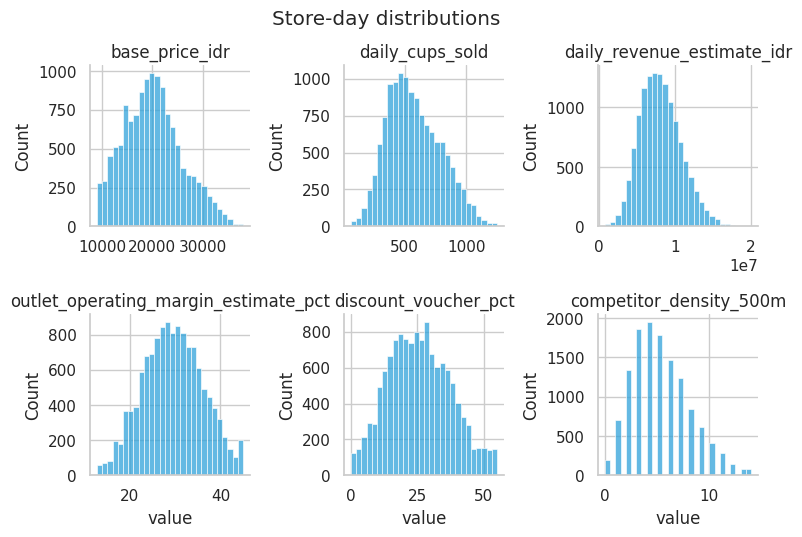

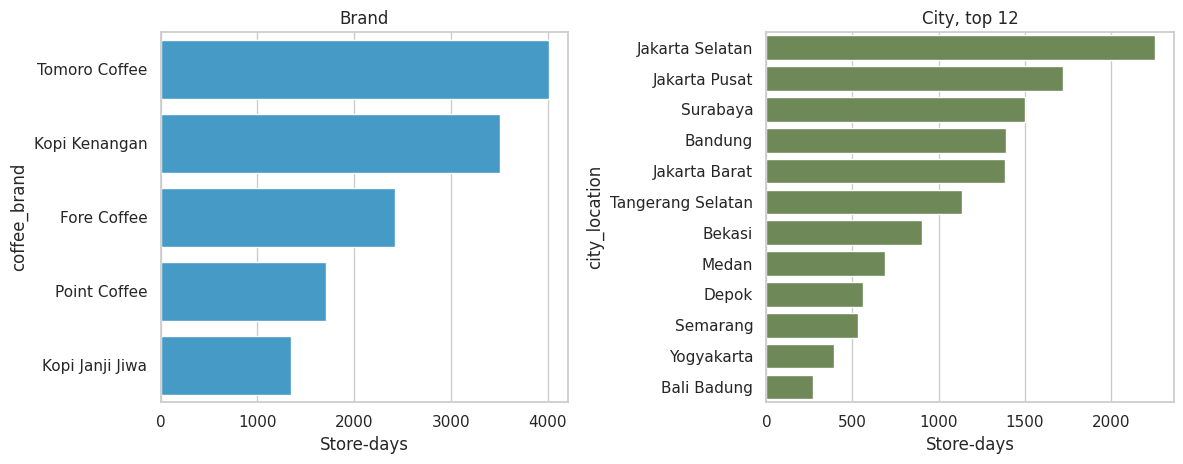

store_format
Standalone Shophouse / Ruko      4501
Mall Kiosk                       3613
Office Tower Lobby               2553
Cloud Kitchen / Delivery Only    1501
Drive-Thru Highway                832
order_method
Mobile App Pickup       5908
Online Ojol Delivery    4332
Dine-In POS Cashier     2760
coffee_beans_type
100% Arabica Specialty      6605
House Blend 70-30           4856
Robusta Blend Commercial    1539
primary_brand_switch_driver
Cheaper-Competitor-Opening       3961
Taste-Inconsistency-Drop         3292
Long-Queue-Pickup-Delay          2758
Lack-Of-Seating-WiFi             1989
Voucher-Exhaustion-Price-Hike    1000


In [3]:
value_cols = [
    "base_price_idr",
    "daily_cups_sold",
    "daily_revenue_estimate_idr",
    "outlet_operating_margin_estimate_pct",
    "discount_voucher_pct",
    "competitor_density_500m",
]
long = df.melt(value_vars=value_cols, var_name="feature", value_name="value")
g = sns.FacetGrid(long, col="feature", col_wrap=3, sharex=False, sharey=False, height=2.6)
g.map_dataframe(sns.histplot, x="value", bins=28, color=PALETTE[0])
g.set_titles("{col_name}")
g.fig.suptitle("Store-day distributions", y=1.03)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
brand_n = df.coffee_brand.value_counts()
sns.barplot(x=brand_n.values, y=brand_n.index, ax=axes[0], color=PALETTE[0])
axes[0].set_xlabel("Store-days")
axes[0].set_title("Brand")
city_n = df.city_location.value_counts().head(12)
sns.barplot(x=city_n.values, y=city_n.index, ax=axes[1], color=PALETTE[3])
axes[1].set_xlabel("Store-days")
axes[1].set_title("City, top 12")
fig.tight_layout()
plt.show()
print(df.store_format.value_counts().to_string())
print(df.order_method.value_counts().to_string())
print(df.coffee_beans_type.value_counts().to_string())
print(df.primary_brand_switch_driver.value_counts().to_string())

**Interpretation:** <br>
Tomoro and Kopi Kenangan contribute the most store-days. Jakarta Selatan, Jakarta Pusat, Surabaya, and Bandung lead the city list, with a long tail of smaller cities. Ruko and mall kiosk are the common formats. App pickup is the most common order method, then ojol delivery, then dine-in. Arabica is the majority bean. The switch-driver list is led by a cheaper competitor, then taste inconsistency, then the queue.

# **4. Brand Price and Volume:** <a id="Brand"></a>

,base_price_idr,daily_cups_sold,daily_revenue_estimate_idr,outlet_operating_margin_estimate_pct,discount_voucher_pct
coffee_brand,,,,,
Tomoro Coffee,14000,808,"7,333,200",25.0,33.7
Kopi Kenangan,22000,593,"9,806,154",30.7,23.2
Point Coffee,19000,444,"7,003,080",36.0,16.5
Fore Coffee,28000,413,"8,376,561",26.9,26.3
Kopi Janji Jiwa,20000,373,"5,934,740",35.8,19.1


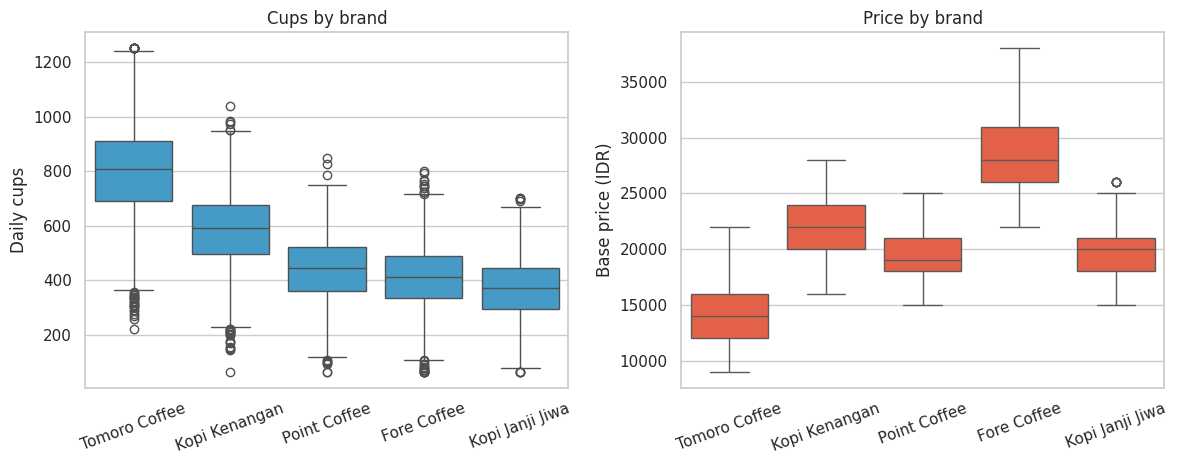

Spearman price vs cups: -0.577 (p=0.000e+00)
Spearman competitor density vs cups: 0.063 (p=9.764e-13)
Spearman rating vs cups: 0.033 (p=2.057e-04)


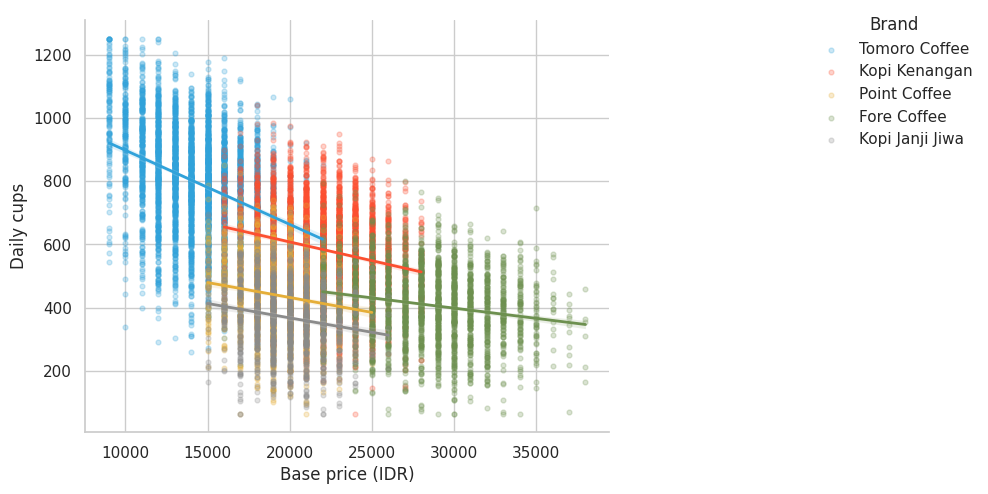

In [4]:
profile = df.groupby("coffee_brand")[
    [
        "base_price_idr",
        "daily_cups_sold",
        "daily_revenue_estimate_idr",
        "outlet_operating_margin_estimate_pct",
        "discount_voucher_pct",
    ]
].median().sort_values("daily_cups_sold", ascending=False)
display(profile.round(1).style.format({
    "base_price_idr": "{:.0f}",
    "daily_cups_sold": "{:.0f}",
    "daily_revenue_estimate_idr": "{:,.0f}",
    "outlet_operating_margin_estimate_pct": "{:.1f}",
    "discount_voucher_pct": "{:.1f}",
}).background_gradient(cmap="Blues"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
brand_order = profile.index.tolist()
sns.boxplot(data=df, x="coffee_brand", y="daily_cups_sold", order=brand_order, ax=axes[0], color=PALETTE[0])
axes[0].set_xlabel("")
axes[0].set_ylabel("Daily cups")
axes[0].set_title("Cups by brand")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="coffee_brand", y="base_price_idr", order=brand_order, ax=axes[1], color=PALETTE[1])
axes[1].set_xlabel("")
axes[1].set_ylabel("Base price (IDR)")
axes[1].set_title("Price by brand")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()

rho_price, p_price = stats.spearmanr(df.base_price_idr, df.daily_cups_sold)
rho_density, p_density = stats.spearmanr(df.competitor_density_500m, df.daily_cups_sold)
rho_rating, p_rating = stats.spearmanr(df.customer_review_rating, df.daily_cups_sold)
print(f"Spearman price vs cups: {rho_price:.3f} (p={p_price:.3e})")
print(f"Spearman competitor density vs cups: {rho_density:.3f} (p={p_density:.3e})")
print(f"Spearman rating vs cups: {rho_rating:.3f} (p={p_rating:.3e})")

g = sns.lmplot(
    data=df,
    x="base_price_idr",
    y="daily_cups_sold",
    hue="coffee_brand",
    hue_order=brand_order,
    height=5,
    aspect=1.3,
    scatter_kws={"s": 12, "alpha": 0.25},
    line_kws={"lw": 2},
)
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Brand", frameon=False)
g.set_axis_labels("Base price (IDR)", "Daily cups")
plt.show()

**Interpretation:** <br>
Price and cups move against each other (Spearman −0.577). Tomoro's median is 14,000 IDR and 808 cups, with the deepest median discount (33.7%) and the thinnest median margin (25.0%). Kopi Kenangan's median is 22,000 IDR, 593 cups, and about 9.81 million IDR of daily revenue, the highest revenue median of the five. Fore is 28,000 IDR, 413 cups, and about 8.38 million IDR. Point Coffee has the highest median margin (36.0%) on a 19,000 IDR price. Rating and competitor density do not separate brands, and neither has a meaningful rank correlation with cups (0.033 and 0.063).

# **5. City, Format, and Nearby Competitors:** <a id="Place"></a>

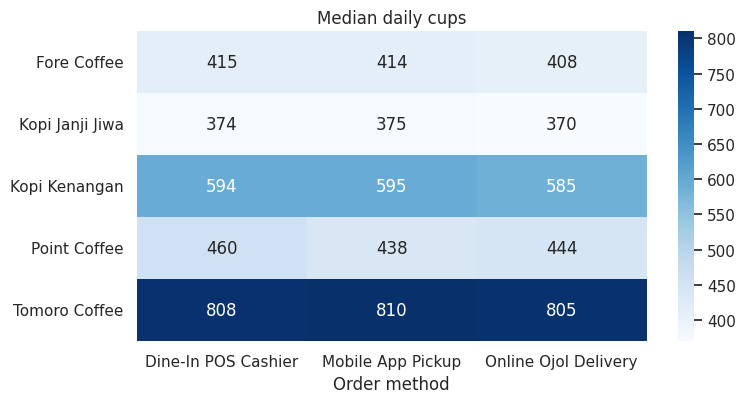

,count,median
customer_brand_loyalty_tier,,
Promo-Chaser-Opportunist,4539,659
Value-Conscious-Regular,5827,523
At-Risk-Churn-Switcher,854,510
Die-Hard-Loyalist,1780,460


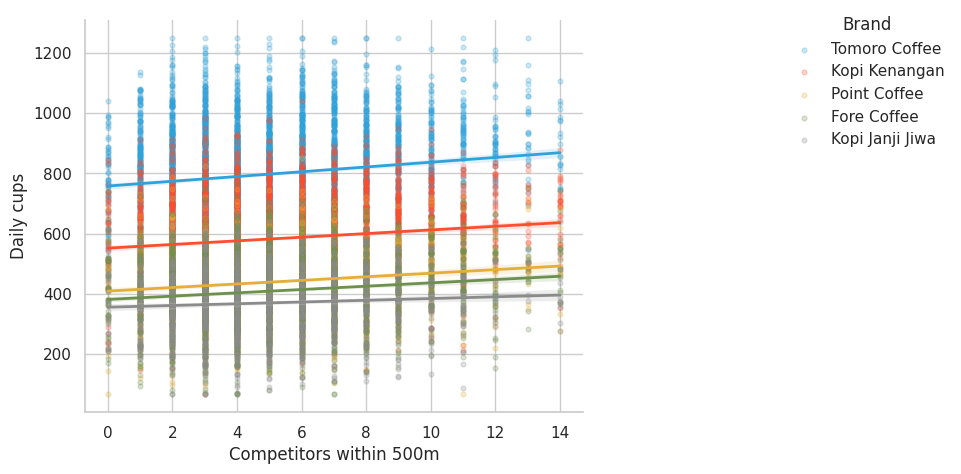

Median cups by order method:
order_method
Dine-In POS Cashier     550.0
Mobile App Pickup       552.0
Online Ojol Delivery    547.0


In [5]:
method_cups = df.pivot_table(
    index="coffee_brand",
    columns="order_method",
    values="daily_cups_sold",
    aggfunc="median",
)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(method_cups, annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set_xlabel("Order method")
ax.set_ylabel("")
ax.set_title("Median daily cups")
fig.tight_layout()
plt.show()

loyalty = (
    df.groupby("customer_brand_loyalty_tier").daily_cups_sold
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)
display(loyalty.style.format({"median": "{:.0f}"}).background_gradient(subset=["median"], cmap="Blues"))

g = sns.lmplot(
    data=df,
    x="competitor_density_500m",
    y="daily_cups_sold",
    hue="coffee_brand",
    hue_order=brand_order,
    height=4.8,
    aspect=1.3,
    scatter_kws={"s": 12, "alpha": 0.25},
    line_kws={"lw": 2},
)
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Brand", frameon=False)
g.set_axis_labels("Competitors within 500m", "Daily cups")
plt.show()
print("Median cups by order method:")
print(df.groupby("order_method").daily_cups_sold.median().round(0).to_string())

**Interpretation:** <br>
Order method is not the volume split. Dine-in, app pickup, and ojol delivery each have a median near 550 cups, and the brand-by-method heatmap keeps the brand order. Nearby competitor count is a flat cloud: the brand lines sit far apart, and density barely tilts them. Loyalty tier medians run from about 460 cups (loyalists) to about 659 (promo-chasers). That spread is smaller than the brand spread, and the tier stays out of the model that follows.

# **6. What Lines Up with Daily Cups:** <a id="Model"></a>

In [6]:
y = df.daily_cups_sold
X = df[["base_price_idr", "competitor_density_500m", "discount_voucher_pct", "coffee_brand"]]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=7)

density_model = LinearRegression().fit(Xtr[["competitor_density_500m"]], ytr)
print("Hold-out R2, cups ~ competitor density:", round(r2_score(yte, density_model.predict(Xte[["competitor_density_500m"]])), 3))
print("Cups per extra competitor:", round(density_model.coef_[0], 2))

price_cols = ["base_price_idr", "competitor_density_500m", "discount_voucher_pct"]
price_model = LinearRegression().fit(Xtr[price_cols], ytr)
print("Hold-out R2, cups ~ price + density + discount:", round(r2_score(yte, price_model.predict(Xte[price_cols])), 3))

pipe = Pipeline([
    ("pre", ColumnTransformer([
        ("num", "passthrough", price_cols),
        ("cat", OneHotEncoder(drop="first"), ["coffee_brand"]),
    ])),
    ("lr", LinearRegression()),
])
pipe.fit(Xtr, ytr)
print("Hold-out R2, those plus brand:", round(r2_score(yte, pipe.predict(Xte)), 3))
print("Reference brand (dropped level):", sorted(df.coffee_brand.unique())[0])
names = pipe.named_steps["pre"].get_feature_names_out()
for name, coef in zip(names, pipe.named_steps["lr"].coef_):
    print(f"{name:48s} {coef:8.2f}")

Hold-out R2, cups ~ competitor density: 0.004
Cups per extra competitor: 5.9
Hold-out R2, cups ~ price + density + discount: 0.405
Hold-out R2, those plus brand: 0.602
Reference brand (dropped level): Fore Coffee
num__base_price_idr                                 -0.01
num__competitor_density_500m                         6.18
num__discount_voucher_pct                            0.27
cat__coffee_brand_Kopi Janji Jiwa                 -149.00
cat__coffee_brand_Kopi Kenangan                     97.93
cat__coffee_brand_Point Coffee                     -85.40
cat__coffee_brand_Tomoro Coffee                    202.34


**Interpretation:** <br>
Competitor density alone has hold-out R² 0.004. Price, density, and discount together reach 0.405. Adding brand reaches 0.602. The dropped brand is Fore Coffee. Against that baseline, Tomoro is about +202 cups, Kopi Kenangan about +98, Point Coffee about −85, and Kopi Janji Jiwa about −149, after price, density, and discount are in the model. The price slope is about −0.01 cups per rupiah, so a 10,000 IDR higher price is about 100 fewer cups. Density's slope stays near 6 cups per extra competitor.

# **7. What It Means — Working Synthesis:** <a id="Synthesis"></a> <br>
Volume in this table is a price and brand story. Tomoro sells the most cups (median 808) at the lowest price (14,000 IDR) and the deepest discount, and its median revenue (about 7.33 million IDR) trails Kopi Kenangan (about 9.81 million IDR at 593 cups and 22,000 IDR). Fore is the expensive end: 28,000 IDR, 413 cups, margin median 26.9%. Point Coffee's margin median is 36.0%.

A hold-out model of daily cups on price, discount, and nearby competitors has R² 0.405. Brand lifts that to 0.602. Density alone is R² 0.004, and every brand has the same median of 5 competitors within 500 meters and the same median rating of 4.5. Order method medians sit together near 550 cups.

**Open follow-ups:** <br>
- A store identifier would separate a busy site from a busy brand. This file is one row per store-day.
- The unique rationale note can be read as text. It has no repeated level to group on.